# Model a cardiovascular outcomes trial in Python

This workbook follows a fictional, randomized, event-driven cardiovascular outcomes trial (CVOT) from design to readout. You'll model time to first three-point major adverse cardiovascular event (MACE), simulate a patient-level dataset, analyze it, and estimate both design power and probability of success (PoS). Later sections compare three- and four-point MACE and size trials with interim efficacy looks.

**Start here.** Open the notebook in Jupyter or VS Code, select a Python kernel, and run all cells. In a clean environment install `numpy pandas scipy matplotlib jupyterlab`. All inputs are editable and all patient records are synthetic. Time is in **years** inside the model. Plot and table labels show where outputs are converted to months.

| Question | Where to work |
|---|---|
| I am new to Python and statistics | 0 · Two small examples you can do by hand |
| How many events do I need for a given HR? | 2 · Event target and power |
| What moves the readout date? | 3–4 · Accrual, hazards, and scenario inputs |
| How is the HR estimated from patient data? | 5 · Analyze one trial |
| How do enrollment and control event rates interact? | 6 · Monte Carlo and the scenario grid |
| What's my chance of a positive result given uncertain efficacy and timing? | 7 · PoS |
| How do I evaluate an actual trial or extend this model? | 8 · Trial diligence and exercises |
| How do MACE-4 and its fourth component change the trial? | 9 · Choose the composite and size the design |
| How do I power a trial with an interim readout? | 10–11 · Alpha spending and simulated interim readouts |


## 0 · Start with a tiny example

If you are new to Python, run the first two cells on their own. Read the comment above each calculation, then compare the printed answer with the arithmetic below. In Jupyter, **Shift+Enter** runs the selected cell and moves to the next one. A name such as `toy_events` holds a value. A line beginning with `#` is a comment for the reader. Python runs code in order and uses indentation to group the body of a function, a loop, or an `if` statement.

| Python you will see | Read it as |
|---|---|
| `x = 10` and `x == 10` | The first stores 10 under the name `x`; the second asks if the current value equals 10 |
| `[4, 8, 12]` and `values[0]` | A list and its first item. `values[-1]` accesses the last item |
| `{"events": 4}` and `row["events"]` | A dictionary of labeled values and a lookup by label |
| `def`, `return`, `for`, `if` | Define a reusable calculation, send back a result, repeat an operation, or run it only when a condition holds |
| `np.array(...)` and `pd.DataFrame(...)` | A numerical array and a table with named columns |
| `f"{value:.1%}"` | Format a decimal as a percentage with one decimal place |

**Four different probabilities or ratios.** Risk is the chance a patient has an event by a specified time. A hazard is the instantaneous event rate among patients still at risk, and an HR compares two of those rates. Alpha is the allowed false-positive rate under the null. Power is the chance a trial wins under specified true assumptions. In a scenario-weighted probability of success (PoS), we average the power across possible assumptions.

**Try it by hand.** If 3 of 100 participants have had MACE by one year with complete follow-up, the observed one-year fraction is 3%. If the trial has 80% power in one world and 40% in a second, weighted 75% and 25%, the overall PoS is $0.75	imes0.80+0.25	imes0.40=0.70$.

In [1]:
# Python starts on the right of = and stores the result under the name on the left.
# Here we have complete one-year follow-up for all 100 patients.
toy_events = 3
toy_patients = 100
toy_one_year_risk = toy_events / toy_patients
print(f"One-year event fraction: {toy_one_year_risk:.1%}")

# Each tuple is (probability this world is true, power if this world is true).
toy_worlds = [(0.75, 0.80), (0.25, 0.40)]
toy_pos = 0.0

# The loop unpacks each tuple into two numbers. Indentation marks the loop body.
for toy_weight, toy_power in toy_worlds:
    toy_contribution = toy_weight * toy_power
    toy_pos = toy_pos + toy_contribution
    print(f"World contribution to PoS: {toy_contribution:.1%}")

# print is outside the loop, so it runs once after both worlds are added.
print(f"Probability of success: {toy_pos:.1%}")

One-year event fraction: 3.0%
World contribution to PoS: 60.0%
World contribution to PoS: 10.0%
Probability of success: 70.0%


### A four-person log-rank example

At month 1, two placebo patients and two treatment patients are still at risk. The first MACE occurs on placebo. Under the null, the expected treated count is $1	imes2/4=0.5$. At month 2 one treated patient is censored. At month 3 one person remains at risk in each arm and the second MACE occurs on placebo, so the expected treated count is again 0.5. The two expected counts sum to 1, while the observed treated count is 0. This workbook uses **expected minus observed**, so a positive result favors treatment. The toy Z is about 1.41 and the two-sided p-value is about 0.157.

Censoring means the last known event-free time is observed. The person contributes to risk sets before that time. In this example they contribute at month 1 and leave before month 3. This tiny dataset is for arithmetic practice. The Normal approximation is intended for much larger event counts.

In [2]:
import math

# A list of dictionaries behaves like a miniature patient table.
# arm=1 means treatment. mace=False means no MACE was observed by that patient's time.
toy_records = [
    {"arm": 0, "month": 1, "mace": True},
    {"arm": 0, "month": 3, "mace": True},
    {"arm": 1, "month": 2, "mace": False},
    {"arm": 1, "month": 4, "mace": False},
]
toy_expected_minus_observed = 0.0
toy_null_variance = 0.0

# There is one MACE at each of these months. The main implementation also handles ties.
for toy_event_month in [1, 3]:
    toy_risk_set = []
    for toy_record in toy_records:
        # Include anyone observed until at least the start of this event time.
        if toy_record["month"] >= toy_event_month:
            toy_risk_set.append(toy_record)

    # Arm is 0 or 1, so summing arm labels counts the treated people.
    toy_treated_at_risk = sum(row["arm"] for row in toy_risk_set)
    toy_share = toy_treated_at_risk / len(toy_risk_set)
    toy_observed_treated = sum(
        row["arm"] for row in toy_risk_set
        if row["month"] == toy_event_month and row["mace"]
    )
    # One event per time: expected count = share; null variance = share*(1-share).
    toy_expected_minus_observed += toy_share - toy_observed_treated
    toy_null_variance += toy_share * (1 - toy_share)
    print(f"Month {toy_event_month}: expected {toy_share:.1f}, observed {toy_observed_treated}")

# Standardize by the square root of variance. erfc gives the two-sided Normal p-value.
toy_z = toy_expected_minus_observed / math.sqrt(toy_null_variance)
toy_p = math.erfc(abs(toy_z) / math.sqrt(2))
print(f"Favorable Z = {toy_z:.3f}, two-sided p = {toy_p:.3f}")

Month 1: expected 0.5, observed 0
Month 3: expected 0.5, observed 0
Favorable Z = 1.414, two-sided p = 0.157


**Next.** Follow one fixed-final example through Sections 1–5 before running the repeated simulations. Sections 9–11 add composite endpoint design and interim monitoring. You can use the settings there and skip the internals of the numerical integration until you are comfortable with the other examples.

## 1 · Specify the trial and the success rule

| Design item | Workbook choice |
|---|---|
| Population | Fictional secondary-prevention population, randomized at entry |
| Endpoint | Time from randomization to first CV death, nonfatal MI, or nonfatal stroke |
| Treatment effect | Hazard ratio (HR) for treatment vs placebo. HR < 1 favors treatment |
| Estimand | Treatment-policy approach to treatment discontinuation. Continue outcome follow-up after discontinuation wherever possible. The modeled event hazards represent the randomized arms |
| Competing event | Non-CV death ends MACE risk. It leaves the risk set for the cause-specific analysis and is represented explicitly in the cumulative incidence |
| Primary test | Unstratified log-rank, two-sided alpha 0.05, with an additional favorable direction requirement for a win. Cox provides the HR and confidence interval |
| Timing | First of the target-event cutoff and a maximum study duration. Analyze at the maximum duration if the event target is missed |
| Research questions | Report statistical win, target attainment, and joint probability of a statistical win and target attainment by a separate deadline |

A protocol can require full enrollment, minimum patient follow-up, adjudicated events, a stratified test, or an alpha-spending plan. Match those rules before forecasting a specific study. Here the floor is a **calendar** floor, and confirmation and database-lock lags are omitted. An early target cutoff can leave some planned participants unrandomized.

## 2 · Event target and power

For treatment allocation fraction $q$, a common proportional-hazards approximation is

$$I \approx Dq(1-q),\qquad D \approx \frac{(z_{1-\alpha/2}+z_{\mathrm{power}})^2}{q(1-q) \log(HR)^2}.$$

$D$ counts people with a **first** primary event across both arms. $I$ approximates information for the log HR. For 1:1 randomization, 90% power, two-sided alpha 0.05, and HR 0.80, round up to **845 events**. At that same target, HR 0.85 gives about **66%** favorable-direction power. The calculation assumes risk-set allocation stays roughly near the randomization ratio. At fixed total events, unequal allocation generally costs information.

Under this approximation, a favorable Z score has mean $-\log(HR)\sqrt I$ and variance 1. A win requires $Z>z_{1-\alpha/2}$. Under the null, the favorable-direction rate is therefore **2.5%** and the two-sided rejection rate is **5%**. If a trial's alternative, endpoint, alpha, interim looks, or test differs, change the calculation and simulation accordingly.

In [3]:
# Imports make existing code available. A dataclass groups named settings; replace() copies
# those settings while changing only the named fields.
from dataclasses import dataclass, replace
from functools import lru_cache

# NumPy and SciPy provide fast numerical operations, root finding, and Normal probabilities.
# The short names np, pd, and plt are aliases used throughout the workbook.
from numpy.polynomial.legendre import leggauss
from math import ceil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.stats import norm

# These settings change the display of numbers and plots. Internal calculations still use
# full numerical precision.
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({
    "figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.19,
})
CONTROL, TREATMENT = "#264653", "#137e76"


def required_events(hr, target_power=0.90, alpha=0.05, allocation=0.5):
    """Schoenfeld approximation for a favorable effect with HR < 1."""
    # A percentage is passed as a decimal: 90% is 0.90. The condition checks that the inputs
    # describe a superiority design with a beneficial HR.
    if not (0 < hr < 1 and 0.5 < target_power < 1
            and 0 < alpha < 1 and 0 < allocation < 1):
        raise ValueError("Check HR, target power, alpha, and allocation.")
    # isf gives the Z cutoff with alpha/2 above it (1.96 at alpha=0.05). ppf gives the Z
    # below which the requested power lies (1.28 at 90%). Add them to obtain the required
    # distance between the null and alternative.
    z = norm.isf(alpha / 2) + norm.ppf(target_power)
    # In Python **2 means square. The denominator is information per event times the squared
    # effect on the log-HR scale. ceil rounds up so we never plan a fraction of an event.
    return ceil(z**2 / (allocation * (1 - allocation) * np.log(hr)**2))


def ph_power(events, hr, alpha=0.05, allocation=0.5):
    """Approximate favorable-direction power at a fixed information level."""
    # Information measures precision. With 50:50 randomization each event contributes about
    # 0.25, so 845 events give about 211 information units.
    information = events * allocation * (1 - allocation)
    # sf means upper-tail probability. Shift the null Z cutoff by the assumed mean under the
    # alternative; log(HR) is negative when treatment helps.
    return norm.sf(norm.isf(alpha / 2) + np.log(hr) * np.sqrt(information))


# Call the function using HR=0.80 and its default arguments. The resulting event target is
# reused throughout the notebook.
target = required_events(0.80)
# A dictionary pairs each column name with its values. The list comprehension calculates one
# power value for each alternative HR.
pd.DataFrame({
    "true HR": [0.75, 0.80, 0.85, 0.90, 1.00],
    "power at fixed target": [ph_power(target, hr) for hr in [0.75, 0.80, 0.85, 0.90, 1.00]],
}).assign(events=target)

,true HR,power at fixed target,events
0,0.750,0.987,845
1,0.800,0.900,845
2,0.850,0.656,845
3,0.900,0.334,845
4,1.000,0.025,845


## 3 · Translate assumptions into event times

**Keep two clocks.** Calendar time starts when the trial opens. Follow-up time starts when a participant is randomized. If someone enrolls at month 18 and has an MI 10 months later, the MI contributes to calendar accrual at month 28 and to the survival risk set at follow-up month 10.

**Convert inputs on the correct scale.** With constant single-event hazard $\lambda$, a one-year net risk $r$ maps to $\lambda=-\log(1-r)$. For a 3% one-year risk, $\lambda=0.03046$ per year. An incidence rate of 3 per 100 person-years is already $0.03$ per year. A published crude event fraction is spread over varying follow-up and cannot be treated as a one-year risk. If you have a one-year *observed cumulative incidence* and an assumed competing-death hazard, solve the competing-risk formula for $\lambda$ instead.

**Allow risk and efficacy to change.** In a piecewise exponential model, each follow-up interval has a constant hazard. Draw $E\sim\mathrm{Exp}(1)$ and solve $H(t)=E$ for that patient's latent event time. If treated HR is 1.0 during the first year and 0.75 thereafter, multiply the placebo hazard by 1.0 and 0.75 in those respective windows. Under delayed benefit, the single Cox HR summarizes the accumulated comparison and depends on follow-up and the risk sets.

**Simulate observation separately.** Draw first MACE, non-CV death, and loss to follow-up, then take the earliest of those and the patient's administrative censoring time. Loss here is an independent observation process. Treatment discontinuation alone does not end event collection under the workbook's estimand.

In [4]:
# A dataclass gives related settings a name and supplies an initializer automatically. Type
# annotations such as n: int describe expected values. frozen=True prevents accidental edits
# after creation; use replace().
@dataclass(frozen=True)
class Design:
    # n is the planned number of people; target counts people with an observed first MACE. In
    # a Python number 12_000 and 12000 are identical.
    n: int = 12_000
    target: int = target
    alpha: float = 0.05
    allocation: float = 0.50
    # All internal calendar values are in years. The minimum is the earliest allowed cutoff,
    # the cap is the latest, and the deadline defines a reporting metric.
    minimum_cut_year: float = 0.0
    cap_year: float = 5.0
    deadline_year: float = 4.0


@dataclass(frozen=True)
class Scenario:
    name: str = "Base"
    # Each enrollment weight describes one calendar month, starting at month zero.
    monthly_weights: tuple = (1.0,) * 24
    # Piecewise intervals: 0–1 year and at least 1 year after randomization.
    breaks: tuple = (0.0, 1.0)
    # The trailing comma makes (value,) a one-item tuple. Multiplying by 2 repeats that value
    # for both follow-up intervals. log1p(-r) accurately computes log(1-r).
    control_mace: tuple = (-np.log1p(-0.03),) * 2
    mace_hr: tuple = (0.80, 0.80)
    noncv_death: float = 0.008       # control cause-specific hazard per year
    death_hr: float = 1.0
    loss_control: float = 0.012      # control loss-to-follow-up hazard per year
    loss_treatment: float = 0.012


# Validation stops the run with a descriptive error before sampling from impossible inputs.
def validate(design, scenario):
    weights = np.asarray(scenario.monthly_weights)
    cuts = np.asarray(scenario.breaks)
    mace = np.asarray(scenario.control_mace)
    hr = np.asarray(scenario.mace_hr)
    if not (design.n >= 2 and 1 <= design.target <= design.n
            and 0 < design.allocation < 1 and 0 < design.alpha < 1
            and 0 <= design.minimum_cut_year <= design.cap_year
            and design.cap_year > 0 and design.deadline_year > 0):
        raise ValueError("Check sample size, event target, allocation, alpha, and calendar rules.")
    if weights.ndim != 1 or not len(weights) or not np.isfinite(weights).all() or min(weights) < 0 or sum(weights) <= 0:
        raise ValueError("Enrollment weights must be nonnegative and have positive total.")
    if (not len(cuts) or cuts[0] != 0 or not np.isfinite(cuts).all()
            or np.any(np.diff(cuts) <= 0) or len(cuts) != len(mace) or len(cuts) != len(hr)):
        raise ValueError("Hazard intervals must start at zero and align with control hazards and HRs.")
    # np.r_ concatenates arrays and individual numbers into a single vector; check all
    # entries together.
    rates = np.r_[mace, hr, scenario.noncv_death, scenario.death_hr,
                  scenario.loss_control, scenario.loss_treatment]
    if not np.isfinite(rates).all() or np.any(rates < 0) or np.any(hr <= 0) or scenario.death_hr <= 0:
        raise ValueError("Hazards must be finite and nonnegative, and HRs must be positive.")


def piecewise_time(rng, breaks, rates, n):
    """Invert the cumulative hazard, moving to the next interval as needed."""
    # Give every participant a random exponential threshold on the cumulative-hazard scale.
    # This is a vector of n thresholds, one number per person.
    remaining = rng.exponential(size=n)
    # Initialize event time to infinity and mark all people active. A Boolean mask is an
    # array of True/False values that selects a subset of participants.
    waiting = np.full(n, np.inf)
    active = np.ones(n, dtype=bool)
    # zip aligns each interval start with its end and hazard. breaks[1:] drops the first
    # start; append infinity as the final interval end.
    for start, stop, rate in zip(breaks, (*breaks[1:], np.inf), rates):
        if rate == 0:
            continue
        # Example: a hazard of 0.04 over 1 year adds 0.04 to cumulative hazard. A person with
        # a remaining threshold of 0.02 crosses halfway through that interval.
        interval_hazard = (stop - start) * rate
        hit = active & (remaining <= interval_hazard)
        waiting[hit] = start + remaining[hit] / rate
        # Remove people whose event has already happened. For the others, subtract the amount
        # accumulated here and carry the remainder into the next interval.
        active[hit] = False
        remaining[active] -= interval_hazard
    return waiting


def exponential_time(rng, rate, n):
    # At a constant positive hazard, exponential waiting time has mean 1/rate. Zero hazard
    # means this event never occurs, represented by infinity.
    return rng.exponential(scale=1 / rate, size=n) if rate > 0 else np.full(n, np.inf)


def simulate_patients(design, scenario, rng):
    """Generate one trial population shared by all snapshots at interim and final."""
    weights = np.asarray(scenario.monthly_weights, dtype=float)
    # Divide the enrollment weights by their sum to get monthly probabilities. For example,
    # weights (1, 3) put 25% of entries in the first month and 75% in the second.
    month = rng.choice(len(weights), size=design.n, p=weights / weights.sum())
    # The uniform draw spreads entries within their assigned months. Divide by 12 to store
    # the entry time in years.
    entry = (month + rng.uniform(size=design.n)) / 12
    # Fixed allocation over planned N, shuffled independently of entry.
    # Create the intended number of assignment labels, then shuffle the labels before
    # attaching them to patients. 0 is placebo and 1 is treatment.
    n_treat = int(round(design.n * design.allocation))
    arm = rng.permutation(np.arange(design.n) < n_treat).astype(int)

    # Reserve space for one MACE time, one competing death time, and one follow-up-loss time
    # per person. The loop fills every element by treatment arm.
    mace = np.empty(design.n)
    death = np.empty(design.n)
    loss = np.empty(design.n)
    for group in (0, 1):
        # This mask is True only for patients in the current group. Summing it gives that
        # group’s sample size because True counts as 1.
        group_mask = arm == group
        n_group = int(group_mask.sum())
        rates = np.asarray(scenario.control_mace)
        # The control hazards are the starting point for both groups. Multiply by the
        # interval-specific HR only in the treatment arm.
        if group == 1:
            rates = rates * scenario.mace_hr
        mace[group_mask] = piecewise_time(rng, scenario.breaks, rates, n_group)
        # Use separate assumptions for non-CV death and loss to follow-up. A non-CV death
        # precludes a future MACE; loss prevents observing a future MACE.
        death_rate = scenario.noncv_death * (scenario.death_hr if group else 1)
        death[group_mask] = exponential_time(rng, death_rate, n_group)
        loss_rate = scenario.loss_treatment if group else scenario.loss_control
        loss[group_mask] = exponential_time(rng, loss_rate, n_group)

    # Only MACE observed before competing death and loss can trigger cutoff.
    eligible = (mace < death) & (mace < loss)
    # Both arrays use the same patient mask. Adding the follow-up time to the entry date
    # converts eligible events to the trial calendar.
    calendar_events = entry[eligible] + mace[eligible]
    return entry, arm, mace, death, loss, eligible, calendar_events


def analyze_snapshot(population, cutoff, keep_data=False):
    """Build the data available at this calendar cutoff and compute its score."""
    # Unpack the tuple in the order returned by simulate_patients(). The underscore is a
    # conventional name for the last item, which this function does not use.
    entry, arm, mace, death, loss, eligible, _ = population
    # Someone enrolled after the snapshot cannot contribute. For included patients, time from
    # entry to cutoff is the maximum follow-up we could observe.
    included = entry < cutoff
    admin = cutoff - entry[included]
    # Calendar comparison avoids dropping the event that defines the cutoff
    # due to floating-point cancellation when calculating cutoff minus entry.
    event = eligible[included] & ((entry[included] + mace[included]) <= cutoff)
    competing = ((death[included] < mace[included]) & (death[included] < loss[included])
                 & ((entry[included] + death[included]) <= cutoff))
    # Take the first of four clocks for each person separately. For analysis use follow-up
    # duration and an event flag, not a single calendar date.
    observed_time = np.minimum.reduce([mace[included], death[included], loss[included], admin])
    observed_time[event] = mace[included][event]
    observed_time[competing] = death[included][competing]
    observed_arm = arm[included]

    risk = risk_sets(observed_time, event, observed_arm)
    z, p_value = logrank(risk)
    d = int(event.sum())
    result = {
        "cutoff_year": cutoff, "n_randomized": int(included.sum()), "events": d,
        "z": z, "p_value": p_value,
    }
    # Return only small trial-level summaries by default. Keep the patient-level table when
    # you want to inspect individual records or fit additional models.
    if keep_data:
        reason = np.select(
            [event, competing, loss[included] < admin],
            ["MACE", "non-CV death", "loss"], default="administrative",
        )
        result["data"] = pd.DataFrame({
            "entry_year": entry[included], "time": observed_time, "arm": observed_arm,
            "event": event, "competing": competing, "reason": reason,
        })
    return result

def simulate_trial(design, scenario, rng, keep_data=False):
    """Analyze once at the event target, calendar floor, or cap."""
    patients = simulate_patients(design, scenario, rng)
    calendar_events = patients[-1]
    # Start with “target never reached.” If enough eligible events occur, find the time of
    # the target event. Python indexes from zero, so the 845th event is at position 844.
    threshold = np.inf
    if len(calendar_events) >= design.target:
        threshold = np.partition(calendar_events, design.target - 1)[design.target - 1]
    # First respect any minimum follow-up calendar floor, then impose the latest permitted
    # analysis date. If the target is never reached, this reduces to the cap.
    cutoff = min(max(threshold, design.minimum_cut_year), design.cap_year)
    result = analyze_snapshot(patients, cutoff, keep_data)
    target_reached = result["events"] >= design.target
    by_deadline = target_reached and cutoff <= design.deadline_year
    # A win requires a sufficiently positive Z under this sign convention. The fixed-design
    # cutoff uses one tail of the two-sided Type I error budget.
    win = result["z"] > norm.isf(design.alpha / 2)
    result.update(target_reached=target_reached, target_cutoff_by_deadline=by_deadline,
                  win=win, on_time_win=win and by_deadline)
    return result

## 4 · Plan the calendar and edit scenarios

Monthly enrollment weights are relative. Twelve weights of 1 followed by twelve weights of 2 assign twice as many expected randomizations per late month as per early month. Zero weights model pauses. All curves below plan the same final sample size. For each calendar horizon, the deterministic projection integrates the probability of an **observed** first MACE over each entry month. It helps check the simulator and separates an expected count from the probability of actually reaching the target.

For constant MACE, competing-death, and independent loss hazards $m,d,l$, the probability of observing first MACE by follow-up $t$ is $m[1-e^{-(m+d+l)t}]/(m+d+l)$. Set $l=0$ for the clinical cumulative incidence under these assumptions. The code applies the same calculation interval by interval.

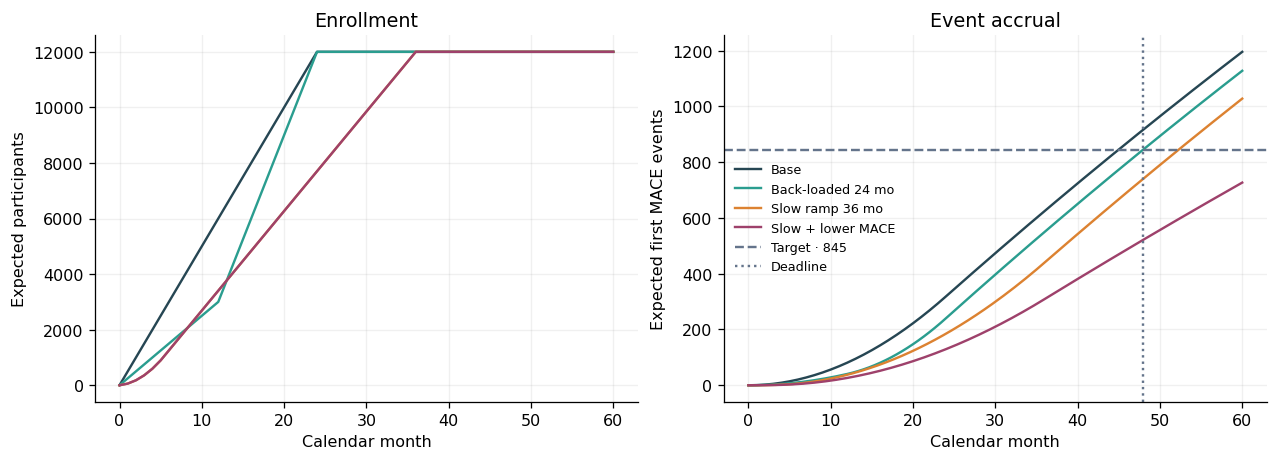

In [5]:
# Instantiate the default trial and base case. These objects separate protocol settings from
# assumptions about what might happen in the trial.
design = Design()
base = Scenario()
ramp = (0.25, 0.50, 0.75, 1.0, 1.25, 1.50)

# Build alternatives by copying the base scenario and overriding specific settings. Comparing
# one change at a time helps isolate its effect.
late = replace(base, name="Back-loaded 24 mo", monthly_weights=(1,) * 12 + (3,) * 12)
slow = replace(base, name="Slow ramp 36 mo", monthly_weights=ramp + (1.50,) * 30)
low = replace(base, name="Lower MACE", control_mace=(-np.log1p(-0.021),) * 2)
high = replace(base, name="Higher MACE", control_mace=(-np.log1p(-0.039),) * 2)
delayed = replace(base, name="Delayed benefit", mace_hr=(1.0, 0.75))
fragile = replace(base, name="More death and loss", noncv_death=0.025,
                  loss_control=0.03, loss_treatment=0.05)
combined = replace(low, name="Slow + lower MACE", monthly_weights=slow.monthly_weights)
scenarios = [base, late, slow, low, high, delayed, fragile, combined]

# Check each case before the slower Monte Carlo cells. Fix the relevant inputs if a
# ValueError appears.
for scenario in scenarios:
    validate(design, scenario)


def mace_probability(follow_up, breaks, mace, death, loss=0):
    """Cumulative probability of MACE before competing death and observation loss."""
    # At time zero everyone is free of recorded MACE, competing death, and loss. Start
    # cumulative observed MACE probability at zero with the same shape as follow_up.
    survival = np.ones_like(follow_up, dtype=float)
    probability = np.zeros_like(follow_up, dtype=float)
    for start, stop, rate in zip(breaks, (*breaks[1:], np.inf), mace):
        # Clamp time in this interval to between zero and the interval length. E.g., 0.8
        # years of follow-up contributes zero years to an interval starting at year 1.
        years = np.clip(follow_up - start, 0, stop - start)
        total = rate + death + loss
        if total > 0:
            # Of those entering this interval, 1-exp(-total*years) have any exit. The
            # fraction rate/total have MACE as that exit. Add only those MACE events to the
            # accumulator.
            probability += survival * (rate / total) * -np.expm1(-total * years)
            # Carry only the fraction with no exit of any type into the next interval. Use
            # loss=0 if you want underlying clinical risk without observation loss.
            survival *= np.exp(-total * years)
    return probability


def expected_calendar(years, design, scenario, steps_per_month=12):
    # Midpoint quadrature of uniform enrollment within each month.
    weights = np.asarray(scenario.monthly_weights, dtype=float)
    # Split each month into equal subgroups. shares is each subgroup’s fraction of planned
    # enrollment and sums to one.
    shares = np.repeat(weights / weights.sum() / steps_per_month, steps_per_month)
    entry = (np.arange(len(shares)) + 0.5) / (12 * steps_per_month)
    # [:, None] turns the calendar dates into a column. Subtracting the row of entry dates
    # builds a date-by-entry-group grid; negative follow-up is set to zero.
    follow_up = np.maximum(np.asarray(years)[:, None] - entry, 0)
    treatment_share = round(design.n * design.allocation) / design.n
    control = mace_probability(follow_up, scenario.breaks, scenario.control_mace,
                               scenario.noncv_death, scenario.loss_control)
    treated = mace_probability(follow_up, scenario.breaks,
                               np.asarray(scenario.control_mace) * scenario.mace_hr,
                               scenario.noncv_death * scenario.death_hr, scenario.loss_treatment)
    # The @ operator takes weighted sums across entry subgroups. Multiplying the weighted
    # fractions by planned N gives expected people and events.
    randomized = design.n * ((follow_up > 0) @ shares)
    events = design.n * (((1 - treatment_share) * control + treatment_share * treated) @ shares)
    return randomized, events


# Create 181 evenly spaced calendar dates and draw the expected curves. The x-axis multiplies
# internal years by 12 to show months.
years = np.linspace(0, design.cap_year, 181)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), layout="constrained")
for case, color in zip([base, late, slow, combined], [CONTROL, "#2a9d8f", "#dc8231", "#9e416b"]):
    randomized, events = expected_calendar(years, design, case)
    axes[0].plot(years * 12, randomized, color=color, label=case.name)
    axes[1].plot(years * 12, events, color=color, label=case.name)
axes[0].set(xlabel="Calendar month", ylabel="Expected participants", title="Enrollment")
axes[1].set(xlabel="Calendar month", ylabel="Expected first MACE events", title="Event accrual")
axes[1].axhline(design.target, ls="--", color="#64748b", label=f"Target · {design.target}")
axes[1].axvline(design.deadline_year * 12, ls=":", color="#64748b", label="Deadline")
axes[1].legend(frameon=False, fontsize=8)
plt.show()

## 5 · Analyze a single simulated trial

At every event follow-up time, count participants still at risk by randomized arm. If 40 of 100 participants at risk are on treatment and 5 events occur, the null expectation is 2 treatment events. Sum observed minus expected treatment events across all times and standardize using the log-rank variance. This notebook flips the score sign so positive Z favors treatment.

Cox uses the same risk sets. For a single event at time $t_j$, the model says that the probability the event comes from the treatment arm, given the event time and risk set, is $n_{1j}e^\beta/(n_{0j}+n_{1j}e^\beta)$. Fit $\beta$ by solving the partial likelihood score equation, then use $HR=e^\beta$. The code uses the Breslow approximation for tied events and a Wald interval. The log-rank score test and Cox Wald inference are closely related under PH. Their p-values can differ.

Use the **Aalen–Johansen cumulative incidence** to describe absolute MACE risk in the presence of non-CV death. Here the MACE cumulative incidence increases by prior all-event survival times the MACE event fraction in the current risk set. The all-event survival falls with both MACE and competing deaths. A cause-specific HR and an absolute risk difference answer different questions.

In [6]:
def risk_sets(time, event, arm):
    """Return control at risk, treated at risk, total events, and treated events."""
    # Sort integer row indices by follow-up duration, then use that same order for time,
    # event and arm so each patient’s values stay together.
    order = np.argsort(time)
    time, event, arm = time[order], event[order], arm[order]
    # Take follow-up times of MACE patients only, then collapse tied times into one row with
    # the total MACE count.
    event_time, n_events = np.unique(time[event], return_counts=True)
    # The first row at a given event time identifies the start of the risk set. side="left"
    # includes anyone with time exactly equal to the event time.
    start = np.searchsorted(time, event_time, side="left")
    # Reverse and cumulatively sum the 0/1 arm labels, then reverse back. Entry i now holds
    # the number of treated patients in rows i through the end.
    treated_tail = np.r_[np.cumsum(arm[::-1])[::-1], 0]
    treated_risk = treated_tail[start]
    control_risk = len(time) - start - treated_risk
    # At each event time, count treatment events. Time-sorted event arrays align.
    event_rows = np.flatnonzero(event)
    # Find where each event-time group starts among the event rows. reduceat sums treatment
    # labels within each group, giving the treated MACE count.
    group_starts = np.r_[0, np.cumsum(n_events)[:-1]]
    treated_events = (np.add.reduceat(arm[event_rows], group_starts)
                      if len(n_events) else np.array([], dtype=int))
    return control_risk, treated_risk, n_events, treated_events


def logrank(risk):
    """Favorable Z and two-sided p-value, with tie-adjusted variance."""
    control, treated, events, treated_events = risk
    total = control + treated
    # At each event time, the null expects the treatment share of events to match the
    # treatment share of the risk set. If 40 of 100 are treated and 5 events occur, expect 2
    # treated events.
    fraction = treated / total
    # For tied events the log-rank count has a finite-population correction. The where
    # argument avoids division by zero when only one person remains.
    tie_factor = np.divide(total - events, total - 1,
                           out=np.zeros_like(fraction), where=total > 1)
    # Add the null variances across event times. Divide expected minus observed by the square
    # root of that variance to get a Z score that is positive when fewer treated patients
    # have MACE.
    variance = np.sum(events * fraction * (1 - fraction) * tie_factor)
    if variance == 0:
        return 0.0, 1.0  # No between-arm information.
    z = np.sum(events * fraction - treated_events) / np.sqrt(variance)
    return z, 2 * norm.sf(abs(z))


def fit_cox(risk, alpha=0.05):
    """Univariate Cox model for a 0/1 treatment indicator, Breslow ties."""
    control, treated, events, treated_events = risk
    # Times when both arms have people at risk provide information about the comparison. An
    # event with only one arm still at risk contributes no information about the treatment
    # coefficient.
    informative = (control > 0) & (treated > 0)
    control, treated = control[informative], treated[informative]
    events, treated_events = events[informative], treated_events[informative]
    if not 0 < treated_events.sum() < events.sum():
        raise ValueError("Finite Cox estimate unavailable with these informative events.")

    # This local function is used only inside fit_cox(). At beta=0 there is no treatment
    # effect; exp(beta) scales the treated event hazard relative to placebo.
    def treatment_fraction(beta):
        weighted_treated = treated * np.exp(beta)
        return weighted_treated / (control + weighted_treated)

    # A positive score means we predicted too few treated events. The fitted beta makes the
    # summed observed-minus-expected count zero.
    def score(beta):
        return np.sum(treated_events - events * treatment_fraction(beta))

    # brentq searches an interval for a zero of score(). The inverse square root of fitted
    # information is the approximate standard error of log HR.
    beta = brentq(score, -30, 30)
    fraction = treatment_fraction(beta)
    se = 1 / np.sqrt(np.sum(events * fraction * (1 - fraction)))
    # Build the Wald interval on the log scale, then exponentiate its endpoints. pd.Series is
    # a labeled vector, here one label per reported statistic.
    critical = norm.isf(alpha / 2)
    return pd.Series({
        "log HR": beta, "SE(log HR)": se, "HR": np.exp(beta),
        "CI low": np.exp(beta - critical * se),
        "CI high": np.exp(beta + critical * se), "Wald p": 2 * norm.sf(abs(beta / se)),
    })


def cumulative_incidence(group):
    """Aalen–Johansen estimate for first MACE with non-CV death competing."""
    time = group["time"].to_numpy()
    # The | means element-wise OR. Track both MACE and non-CV death to calculate the
    # probability of reaching each time free of either event.
    failures = group["event"].to_numpy() | group["competing"].to_numpy()
    times, all_failures = np.unique(time[failures], return_counts=True)
    at_risk = len(time) - np.searchsorted(np.sort(time), times)
    mace_failures = np.bincount(
        np.searchsorted(times, time[group["event"].to_numpy()]), minlength=len(times))
    # Compute the product of survival fractions up to just before each event time. The MACE
    # increment is this survival probability times MACE events divided by the current risk
    # set.
    prior_survival = np.r_[1.0, np.cumprod(1 - all_failures / at_risk)[:-1]]
    incidence = np.cumsum(prior_survival * mace_failures / at_risk) if len(times) else np.array([])
    return np.r_[0.0, times], np.r_[0.0, incidence]


# Set a random seed so a rerun gives the same example. The string key "data" selects the
# participant table from the returned dictionary.
one = simulate_trial(design, base, np.random.default_rng(20261123), keep_data=True)
patients = one["data"]
print(f"{one['events']} first MACE events at month {12 * one['cutoff_year']:.1f}")
print(f"Log-rank p = {one['p_value']:.4g}   |   Favorable Z = {one['z']:.3f}")
fit_cox(risk_sets(patients["time"].to_numpy(), patients["event"].to_numpy(),
                  patients["arm"].to_numpy())).to_frame("estimate")

845 first MACE events at month 45.5
Log-rank p = 2.235e-06   |   Favorable Z = 4.731


,estimate
log HR,-0.328
SE(log HR),0.070
HR,0.720
CI low,0.629
CI high,0.826
Wald p,0.000


Placebo: 24-month MACE risk 5.97%; 4,844 at risk just before 24 months
Treatment: 24-month MACE risk 4.30%; 4,963 at risk just before 24 months
24-month absolute risk reduction: 1.68 percentage points


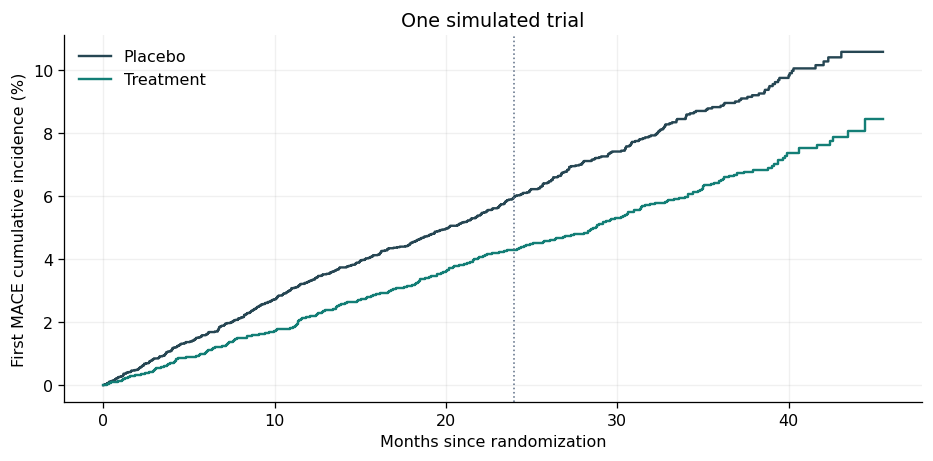

arm,placebo,treatment
reason,,
MACE,487,358
administrative,5187,5348
loss,205,184
non-CV death,121,110


In [7]:
fig, ax = plt.subplots(figsize=(8, 3.9), layout="constrained")
horizon = 2.0  # Prespecified horizon in years from randomization
risk_at_horizon = {}
for arm_value, label, color in [(0, "Placebo", CONTROL), (1, "Treatment", TREATMENT)]:
    # Filter a pandas table by a True/False column condition. Read each arm’s step function
    # at the same follow-up horizon so the risks are comparable.
    group = patients[patients["arm"] == arm_value]
    times, cif = cumulative_incidence(group)
    ax.step(np.r_[times, group["time"].max()] * 12, np.r_[cif, cif[-1]] * 100,
            where="post", color=color, label=label)
    # Search for the first event time after the horizon, then step back one index to read the
    # most recent cumulative incidence.
    risk_at_horizon[label] = cif[np.searchsorted(times, horizon, side="right") - 1]
    print(f"{label}: 24-month MACE risk {100 * risk_at_horizon[label]:.2f}%; "
          f"{(group['time'] >= horizon).sum():,} at risk just before 24 months")
ax.axvline(horizon * 12, color="#64748b", ls=":", lw=1)
ax.set(xlabel="Months since randomization", ylabel="First MACE cumulative incidence (%)",
       title="One simulated trial")
ax.legend(frameon=False)
plt.show()
print(f"24-month absolute risk reduction: "
      f"{100 * (risk_at_horizon['Placebo'] - risk_at_horizon['Treatment']):.2f} percentage points")
pd.crosstab(patients["reason"], patients["arm"]).rename(columns={0: "placebo", 1: "treatment"})

## 6 · Simulate power and timing across scenarios

Each simulated trial produces a calendar cutoff, event count, and test result. Repeating the trial with the *same* assumptions estimates conditional power. Repeat under equal MACE and censoring hazards in both arms to check the null rejection rate. The approximate Monte Carlo standard error of a simulated proportion is $\sqrt{p(1-p)/B}$ for $B$ independent trials. Around 50%, 500 replicates give about 2.2 percentage points of simulation SE. Increase replicates before interpreting small differences. The uncertainty from model assumptions is separate.

Timing columns show the median and 90th percentile **among trials that reach target**. Look at target attainment and event counts alongside those dates. A cutoff at the 60-month cap with insufficient events still generates a primary test in this design. If your decision rule requires the target before testing, use the joint outcome or change the protocol rule in the simulator.

In [8]:
def simulate_many(design, scenario, n_sims, seed):
    validate(design, scenario)
    rng = np.random.default_rng(seed)
    # The list comprehension runs the patient simulator n_sims times. Each iteration advances
    # the same generator; each returned dictionary becomes one DataFrame row.
    return pd.DataFrame([simulate_trial(design, scenario, rng) for _ in range(n_sims)])


def summarize(trials, alpha=0.05):
    # A Boolean mean is the fraction of trials that crossed the efficacy threshold. Timing
    # quantiles below use only trials reaching the target, so read them alongside target
    # attainment.
    win = trials["win"].mean()
    hit_month = 12 * trials.loc[trials["target_reached"], "cutoff_year"]
    hit_quantiles = hit_month.quantile([0.5, 0.9])
    # The estimated Monte Carlo SE describes noise from a finite number of simulations.
    # Increase the replicate count for a more precise simulation estimate.
    return {
        "Power %": 100 * win,
        "Power MC SE (pp)": 100 * np.sqrt(win * (1 - win) / len(trials)),
        "Two-sided reject %": 100 * (trials["p_value"] < alpha).mean(),
        "Target by cap %": 100 * trials["target_reached"].mean(),
        "Target cutoff by deadline %": 100 * trials["target_cutoff_by_deadline"].mean(),
        "Win + target by deadline %": 100 * trials["on_time_win"].mean(),
        "Median events at cutoff": trials["events"].median(),
        "Median target cutoff (mo)": hit_quantiles.loc[0.5],
        "P90 target cutoff (mo)": hit_quantiles.loc[0.9],
    }


N_SIMS = 500  # Try 100 to iterate quickly, then raise to 2,000–10,000 for precision.
null_case = replace(base, name="Null check", mace_hr=(1.0, 1.0))
all_cases = [*scenarios, null_case]
# This dictionary stores one trial-results table per named case. enumerate supplies a
# separate reproducible seed for each case.
runs = {
    case.name: simulate_many(design, case, N_SIMS, 8800 + i)
    for i, case in enumerate(all_cases)
}
summary = pd.DataFrame({
    name: summarize(trials, design.alpha) for name, trials in runs.items()
}).T
summary.round(1)

,Power %,Power MC SE (pp),Two-sided reject %,Target by cap %,Target cutoff by deadline %,Win + target by deadline %,Median events at cutoff,Median target cutoff (mo),P90 target cutoff (mo)
Base,90.200,1.300,90.200,100.000,99.600,89.800,845.000,45.000,46.500
Back-loaded 24 mo,88.400,1.400,88.400,100.000,48.800,43.000,845.000,48.000,49.500
Slow ramp 36 mo,90.000,1.300,90.000,100.000,0.000,0.000,845.000,52.400,53.900
Lower MACE,89.600,1.400,89.600,51.800,0.000,0.000,845.000,58.700,59.800
Higher MACE,88.400,1.400,88.400,100.000,100.000,88.400,845.000,37.000,38.200
Delayed benefit,70.800,2.000,70.800,100.000,99.800,70.600,845.000,44.100,45.600
More death and loss,90.400,1.300,90.400,100.000,73.200,66.200,845.000,47.200,49.000
Slow + lower MACE,84.600,1.600,84.600,0.000,0.000,0.000,727.000,NaN,NaN
Null check,1.800,0.600,4.600,100.000,100.000,1.800,845.000,41.500,43.000


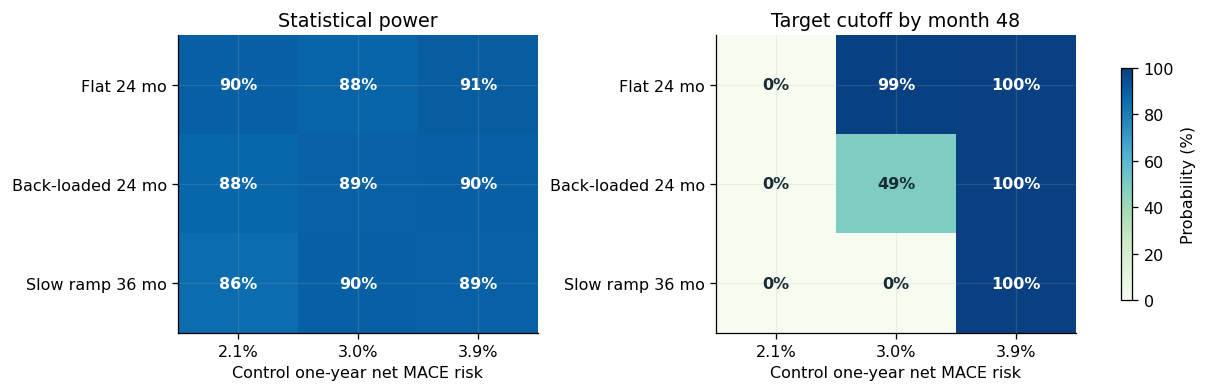

In [9]:
# Cross enrollment curves with one-year net MACE risk, keeping HR fixed at 0.80.
risks = [0.021, 0.030, 0.039]
curves = {"Flat 24 mo": base, "Back-loaded 24 mo": late, "Slow ramp 36 mo": slow}
# Start an empty list. The outer loop picks an enrollment curve; the inner loop applies every
# event rate to that curve and appends one summary row.
grid_rows = []
for i, (label, curve) in enumerate(curves.items()):
    for j, control_risk in enumerate(risks):
        grid_case = replace(curve, control_mace=(-np.log1p(-control_risk),) * 2)
        grid_trials = simulate_many(design, grid_case, N_SIMS, 9500 + 10 * i + j)
        grid_rows.append({"Enrollment": label, "Control risk": f"{control_risk:.1%}",
                          **summarize(grid_trials, design.alpha)})
grid = pd.DataFrame(grid_rows)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.3), layout="constrained")
for ax, metric, title in zip(
    axes,
    ["Power %", "Target cutoff by deadline %"],
    ["Statistical power", "Target cutoff by month 48"],
):
    # pivot reshapes a long table into one number per row-column combination for the heatmap.
    # reindex restores the order of the scenarios.
    values = grid.pivot(index="Enrollment", columns="Control risk", values=metric)
    values = values.reindex(list(curves))
    plot = ax.imshow(values, vmin=0, vmax=100, cmap="GnBu", aspect="auto")
    ax.set_xticks(range(len(risks)), values.columns)
    ax.set_yticks(range(len(curves)), values.index)
    ax.set(xlabel="Control one-year net MACE risk", title=title)
    for i, row in enumerate(values.to_numpy()):
        for j, value in enumerate(row):
            ax.text(j, i, f"{value:.0f}%", ha="center", va="center",
                    color="white" if value > 68 else "#172b35", fontweight="bold")
fig.colorbar(plot, ax=axes, shrink=0.78, label="Probability (%)")
plt.show()

For an event-driven design, slower enrollment or lower background risk may mostly shift the target date when the trial can wait long enough. Under a hard cap, those same changes can reduce the number of events and power. A fixed-date analysis is a special case: set `minimum_cut_year` equal to `cap_year`. Inspect the realized allocation and the achieved event count before using the fixed-information approximation.

## 7 · Calculate probability of success

**Power** conditions on specified true inputs. **PoS** (also called assurance here) averages the chance of passing your success rule over uncertainty in those inputs. Define separate outputs for a positive primary result and a positive result with the target-based cutoff reached by a deadline. The latter is an operational milestone, distinct from approval or the actual announcement date.

Start with discrete worlds you can explain. Below the weights are illustrative judgments, with one world holding the control and operational assumptions at base but assuming no benefit. Keeping inputs together in a world lets you express dependencies. For example, background treatment uptake could lower placebo risk and also lower incremental benefit. The weighted estimate conditions on the chosen worlds and weights.

In [10]:
# Each tuple pairs a weight with the scenario it applies to. Weights represent uncertainty
# over what is true in a future trial.
worlds = [
    (0.25, replace(high, name="Upside", mace_hr=(0.75, 0.75))),
    (0.45, base),
    (0.20, replace(combined, name="Downside", mace_hr=(0.90, 0.90))),
    (0.10, null_case),
]
# assert stops execution if its condition is false. These checks ensure the world weights are
# valid probabilities before calculating their weighted average.
assert np.isclose(sum(weight for weight, _ in worlds), 1)
assert all(weight >= 0 for weight, _ in worlds)

rows = []
for world_number, (weight, case) in enumerate(worlds):
    trials = runs[case.name] if case in (base, null_case) else simulate_many(
        design, case, N_SIMS, 19000 + world_number)
    # Compute power conditional on this world first. Multiply by the world’s weight before
    # adding it to the overall probability of success.
    power = trials["win"].mean()
    on_time = trials["on_time_win"].mean()
    rows.append({
        "World": case.name, "Weight": weight,
        "Control 1-y net risk": -np.expm1(-case.control_mace[0]),
        "Early HR": case.mace_hr[0], "Late HR": case.mace_hr[-1],
        "Power": power, "On-time success": on_time,
        "Weighted power": weight * power, "Weighted on-time": weight * on_time,
        "Variance contribution": weight**2 * power * (1 - power) / len(trials),
        "On-time variance contribution": weight**2 * on_time * (1 - on_time) / len(trials),
    })

# Changing the row index makes world labels easier to find. The variance of a sum of
# independent weighted estimates uses squared weights.
world_table = pd.DataFrame(rows).set_index("World")
print(f"Statistical PoS: {world_table['Weighted power'].sum():.1%} "
      f"(MC SE {world_table['Variance contribution'].sum()**0.5:.2%})")
print(f"PoS with target cutoff by month {12 * design.deadline_year:.0f}: "
      f"{world_table['Weighted on-time'].sum():.1%} "
      f"(MC SE {world_table['On-time variance contribution'].sum()**0.5:.2%})")
world_table.drop(columns=["Variance contribution", "On-time variance contribution"])

Statistical PoS: 71.4% (MC SE 0.74%)
PoS with target cutoff by month 48: 65.3% (MC SE 0.62%)


,Weight,Control 1-y net risk,Early HR,Late HR,Power,On-time success,Weighted power,Weighted on-time
World,,,,,,,,
Upside,0.250,0.039,0.750,0.750,0.988,0.988,0.247,0.247
Base,0.450,0.030,0.800,0.800,0.902,0.898,0.406,0.404
Downside,0.200,0.021,0.900,0.900,0.298,0.000,0.060,0.000
Null check,0.100,0.030,1.000,1.000,0.018,0.018,0.002,0.002


### Continuous uncertainty in efficacy and event rate

Draw one set of **trial-level** assumptions for each replicate. A Normal distribution on log HR places the median at the chosen central HR and allows null or harmful true effects. Pick its spread from a predictive interval you can defend and test wider and narrower alternatives. A previous estimate's sampling SE alone does not account for transport to a new population, background therapy, regimen, or endpoint.

The example below imposes an illustrative negative correlation on log hazard and log HR. It pairs lower event hazards with weaker treatment effects on average. Where you have only a fixed event target and PH, averaging analytical power over the efficacy draws is a quick benchmark. The patient simulation also accounts for the cutoff and missed target.

In [11]:
def draw_worlds(rng, n, correlation=-0.45):
    # Marginal medians: HR 0.83 and control net 1-year MACE risk 3%.
    sd_log_hr, sd_log_hazard = 0.12, 0.30
    # A covariance matrix contains variances on its diagonal and covariance off the diagonal.
    # This choice lets efficacy and background risk move together across trial replicates.
    covariance = correlation * sd_log_hr * sd_log_hazard
    return rng.multivariate_normal(
        mean=[np.log(0.83), np.log(base.control_mace[0])],
        cov=[[sd_log_hr**2, covariance], [covariance, sd_log_hazard**2]],
        size=n,
    )


rng = np.random.default_rng(33001)
log_hr_and_rate = draw_worlds(rng, 700)
predictive_runs = []
for log_hr, log_hazard in log_hr_and_rate:
    # Exponentiate the joint log-scale draw to get a positive HR and hazard. Across
    # participants within this trial these two assumptions are fixed.
    hr, hazard = np.exp([log_hr, log_hazard])
    case = replace(base, mace_hr=(hr, hr), control_mace=(hazard, hazard))
    predictive_runs.append(simulate_trial(design, case, rng))
predictive = pd.DataFrame(predictive_runs)

pd.Series({
    "Fixed-target analytical PoS": ph_power(design.target, np.exp(log_hr_and_rate[:, 0])).mean(),
    "Simulated PoS": predictive["win"].mean(),
    "Target by cap": predictive["target_reached"].mean(),
    "Simulated PoS with target cutoff by deadline": predictive["on_time_win"].mean(),
}).to_frame("probability")

,probability
Fixed-target analytical PoS,0.634
Simulated PoS,0.643
Target by cap,0.911
Simulated PoS with target cutoff by deadline,0.476


For blinded updates, condition calendar forecasts on actual enrollment and observed **pooled** events. A pooled count informs overall accrual but generally cannot identify the treatment HR on its own. For unblinded interim predictive power, use authorized arm-specific evidence to update the model and account for the already observed test statistic, remaining information, and prespecified decision boundaries. Simulating a fresh fixed-final trial given an updated HR distribution does not reproduce an interim conditional prediction.

## 8 · Evaluate an actual CV trial

| What to check | How to translate it into the model |
|---|---|
| Exact endpoint and analysis set | Match first 3P-MACE, expanded MACE, first HF event, recurrent HF hospitalizations, or another endpoint. Confirm event definitions, adjudication rules, censoring, ITT population, stratification, and test |
| Background risk | Use control-arm cumulative incidence at multiple time points when available. For cause-specific calibration, use relevant survival/competing-event summaries and fit intervals jointly. Check age, prior events, geography, disease severity, and current standard of care |
| Patient mix | Model distinct strata with their own enrollment, baseline hazards, and treatment effects if needed. A shifting patient mix can change pooled accrual even if total enrollment follows plan |
| Event target and clock | Reconcile whether counts are suspected, adjudicated, or final. Use enrollment, actual or projected dropout, minimum follow-up, interim rules, and lock lag. Mature trials may have substantial time between the event cutoff and publication |
| Relative and absolute effect | Read the HR with its CI, then examine fixed-horizon absolute MACE risk, follow-up support, endpoint components, and all-cause mortality. Report the uncertainty on both scales in a real analysis |
| Nonproportional hazards | Inspect curves, time-varying estimates, and diagnostics such as Schoenfeld residuals in production software. Simulate delayed, waning, or crossing effects and apply the actual prespecified analysis. For time to first event of any cause, RMST is another interpretable summary. Choose the competing-risk estimand separately for MACE |
| MACE components | Simulate cause-specific first CV death, MI, and stroke times (plus non-CV death). The sum of component hazards is the first-MACE hazard while event-free. At time $t$, the composite HR is the control-hazard-weighted mean of the component HRs at that time. Check a scenario where the frequent component drives most of the composite benefit |
| Competing death and missingness | Compare cause-specific and absolute effects. Stress-test differential death and observation loss. If loss is informative, consider jointly simulating risk and censoring, then prespecify sensitivity analyses. Censoring at treatment stop would change what you estimate |
| First vs recurrent HF events | For recurrent HF hospitalizations plus CV death, simulate repeated hospitalizations within patients, account for dependence across events and terminal death, and fit the planned estimator, such as a proportional-rates or joint frailty approach. First-event power formulas do not carry over |
| Noninferiority or multiple looks | Use the prespecified margin, sidedness, information fractions, and alpha boundaries. For HR-margin noninferiority, success typically requires the prespecified upper CI bound below the margin; the approximate distance on the log scale is $\log(M)-\log(HR_\mathrm{true})$ for margin $M$. Simulate the actual testing sequence and check type I error at the relevant null boundary |

**Worked example · SELECT.** In SELECT, the primary first-event composite was CV death, nonfatal MI, or nonfatal stroke. Published counts were 569/8,803 on semaglutide and 701/8,801 on placebo, with mean follow-up of 39.8 months. The reported HR was 0.80 (95% CI 0.72–0.90). Use the reported HR to anchor an efficacy scenario only if the comparison is relevant. Use time-specific placebo incidence data and numbers at risk to calibrate the accrual model. The crude fractions below show why a risk ratio and a Cox HR are separate quantities, even when they are numerically close.

**How to bring your own inputs.** Paste monthly enrollment into `monthly_weights` in order, preserving months with zero randomizations. Change `breaks` and `control_mace` together to set follow-up-specific risks. For patient-level analysis, the minimum columns in the worked example are `time`, `arm`, `event`, and `competing`. Use time since randomization, one row per randomized participant, treatment coded 1, and mutually exclusive MACE and competing indicators. The risk-set functions expect NumPy arrays with Boolean event indicators; validate patient records before analysis. Use a validated survival-analysis package for protocol execution and for covariates, stratification, diagnostics, and interval estimates for absolute risk.

**Exercises**

1. Reduce enrollment by month without changing total planned N. Compare the median target date and power before and after extending the study cap.
2. Replace the uniform 3% net-risk hazard with 0.06 in year one and 0.02 thereafter. Compare event counts at months 36, 48, and 60.
3. Compare early HR 1.0 / late HR 0.75 with constant HR 0.80. Fit Cox on representative datasets and explain why enrollment and follow-up change the comparison under delayed efficacy.
4. Shift 10 percentage points of prior weight from the upside world to the null world. Compare the new statistical and on-time PoS.
5. Calibrate one real trial to published control cumulative-incidence points and compare projected enrollment, events by cut date, and follow-up against the publication. Keep design assumptions distinct from observed results.

In [12]:
# SELECT arithmetic from the publication. These calculations do not fit patient data.
# A crude fraction divides the number of participants having an event by the number
# randomized, even if those patients contributed different follow-up lengths.
placebo_fraction = 701 / 8801
treatment_fraction = 569 / 8803
# Back-solve from rounded 95% CI endpoints. This SE and p-value are approximate.
select_se = (np.log(0.90) - np.log(0.72)) / (2 * norm.isf(0.025))
pd.Series({
    "Placebo crude fraction": placebo_fraction,
    "Treated crude fraction": treatment_fraction,
    "Crude fraction ratio": treatment_fraction / placebo_fraction,
    "Reported Cox HR": 0.80,
    "Approx. SE(log HR) from rounded CI": select_se,
}).to_frame("value")

,value
Placebo crude fraction,0.080
Treated crude fraction,0.065
Crude fraction ratio,0.812
Reported Cox HR,0.800
Approx. SE(log HR) from rounded CI,0.057


### Calibrate placebo hazards from a published curve

This example uses synthetic cumulative incidences as a stand-in for values read from a placebo curve. Assume a constant non-CV death hazard of 0.008/year and calibrate one MACE hazard per interval to match the 12- and 36-month values. Fit to the clinical CIF with loss set to zero, then add loss when projecting observed events. If the publication reports $1-\mathrm{KM}$ with competing deaths censored, calibrate to that curve's net-risk scale or obtain suitable competing-risk data. A single published event fraction and mean follow-up cannot identify this hazard shape.

In [13]:
# These two synthetic targets are risks at known years of follow-up. Calibration chooses the
# hazard inputs so the model probabilities match the targets.
published_times = np.array([1.0, 3.0])
published_cif = np.array([0.035, 0.080])  # Synthetic fixed-horizon risks
competing_death_hazard = 0.008

# brentq changes the first-interval hazard until predicted 12-month risk minus the target is
# zero. The two numbers at the end of the call are the bracket searched.
early = brentq(
    lambda rate: mace_probability(published_times[:1], (0.0,), (rate,),
                                  competing_death_hazard)[0] - published_cif[0],
    0.0, 2.0,
)
# Hold the already fitted first-year hazard fixed. Choose the second-interval hazard so the
# risk at year 3, which includes both intervals, matches the second target.
late_rate = brentq(
    lambda rate: mace_probability(published_times[1:], (0.0, 1.0), (early, rate),
                                  competing_death_hazard)[0] - published_cif[1],
    0.0, 2.0,
)
calibrated = replace(base, name="Calibrated placebo", control_mace=(early, late_rate),
                     noncv_death=competing_death_hazard)
print(f"Calibrated MACE hazards per 100 person-years: {100 * early:.2f}, {100 * late_rate:.2f}")
_, projected_events = expected_calendar(np.array([3.0, 4.0, 5.0]), design, calibrated)
pd.Series(projected_events, index=[36, 48, 60], name="Expected events").rename_axis("Calendar month").to_frame()

Calibrated MACE hazards per 100 person-years: 3.58, 2.43


,Expected events
Calendar month,
36,618.239
48,851.828
60,"1,075.788"


## 9 · Choose the composite and size the design

| Trial | Composite | Why the distinction matters |
|---|---|---|
| SELECT | CV death, nonfatal MI, nonfatal stroke | A reference for a three-point MACE efficacy trial in overweight or obesity with established CV disease |
| ELIXA | CV death, MI, stroke, or hospitalization for unstable angina | Example of a four-component endpoint after acute coronary syndrome. The upper 95% HR CI needed to be below 1.30 for noninferiority and below 1.00 for superiority |
| FOURIER | CV death, MI, stroke, hospitalization for unstable angina, or coronary revascularization | The primary composite included five components. CV death, MI, or stroke was the key secondary composite |

Sources for definitions and populations are linked in the references. **Write out MACE-4's exact fourth component** in your model. The teaching example adds hospitalization for unstable angina. If the protocol instead adds urgent coronary revascularization, replace both the definition and its inputs. For acute coronary syndrome, the EMA guideline discusses variability and clinical-practice dependence in diagnosing unstable angina.

### How ELIXA was designed

The FDA review describes a plan for about 6,000 participants over 37 months of enrollment, about 10 further months of follow-up, and 844 positively adjudicated first events. It reports assumed annual event rates of 10% in the first year and 7% thereafter, and about 96% planned power for the final 1.30 noninferiority margin. The review describes an earlier analysis after 263 participants with primary events to address the separate 1.80 margin. The final 1.30 hypothesis did not have a planned interim analysis. The publication reported 805 primary events across 6,068 participants. This illustrates why the protocol's hypothesis, planned target, interim objective, and final reported count belong in separate fields.

### From protocol to event target and sample size

| Step | Inputs to take from the protocol or benchmark |
|---|---|
| 1. Choose the hypothesis | Superiority against HR 1.0 or noninferiority against margin $M$. Record comparison direction, target power, alpha, planned looks, and multiplicity strategy |
| 2. Estimate the component mix | Match population, adjudication, event definitions, follow-up, and current standard of care. Prefer event-free risk sets and first-event component data. A published all-occurrence component table can count the same patient several times |
| 3. Specify treatment effects by component | Convert component hazards into control and treatment composite hazards. Include neutral fourth-component scenarios, post-ACS front-loading, treatment delay, and loss to follow-up |
| 4. Size the information target | Use Schoenfeld as a fixed-final starting point when PH is plausible. Use the sequential calculation in Section 10 for planned interim stopping. For time-varying effects, size to simulated operating characteristics |
| 5. Convert events into people and time | At a candidate N and calendar cap, integrate expected observed event yield over enrollment. Then simulate the probability of reaching the target, achieved power, cutoff dates, participant follow-up and the chance of a positive result by a deadline |
| 6. Test robustness | Stress background rates, enrollment, changing patient mix, attrition, follow-up, and the efficacy of each component. Check superiority type I error under HR 1 or noninferiority at the margin. Check analyzable events and actual information at each look |

For first events, the composite hazard while still event-free is the sum of its component hazards. The time-specific composite HR is $\sum_k \lambda_{Ck}(t) HR_k(t)/\sum_k \lambda_{Ck}(t)$. A frequent fourth event with weak treatment benefit can speed accrual and pull the composite HR toward 1. The examples below give the fourth event the same baseline incidence but two different treatment effects.

For fixed-final **noninferiority**, the approximate effect distance is $\log(M)-\log(HR_{\rm true})$ and favorable Z is measured against $\log(M)$. At 1:1, with one-sided alpha 0.025, 90% power and a true HR of 1.0, an illustrative margin of 1.30 gives about 611 events. The margin needs clinical and regulatory justification. The interim simulator below uses superiority at HR 1.0.

In [14]:
@dataclass(frozen=True)
# A component holds one control hazard and one HR per interval. This lets different types of
# events have different frequencies and treatment effects.
class Component:
    label: str
    control: tuple
    hr: tuple


mace3_components = (
    Component("CV death", (0.008, 0.008), (0.82, 0.82)),
    Component("Nonfatal MI", (0.014, 0.014), (0.77, 0.77)),
    Component("Nonfatal stroke", (0.0085, 0.0085), (0.82, 0.82)),
)
angina = Component("Hospitalization for unstable angina", (0.010, 0.010), (1.0, 1.0))
mace4_components = (*mace3_components, angina)
mace4_benefit = (*mace3_components, replace(angina, hr=(0.78, 0.78)))


def composite_scenario(template, name, components):
    # Rows are endpoint components and columns are follow-up intervals. Multiplying hazards
    # by HRs element by element gives the treated hazards.
    control = np.asarray([component.control for component in components], dtype=float)
    effects = np.asarray([component.hr for component in components], dtype=float)
    if (control.shape != effects.shape or control.shape[1] != len(template.breaks)
            or not np.isfinite(control).all() or not np.isfinite(effects).all()
            or np.any(control < 0) or np.any(effects <= 0)):
        raise ValueError("Give each component a nonnegative hazard and positive HR per interval.")
    # axis=0 sums down the rows. Divide the sum of treatment hazards by the sum of control
    # hazards, separately for each interval, to get the composite HR.
    control_total = control.sum(axis=0)
    treated_total = (control * effects).sum(axis=0)
    if np.any(control_total <= 0):
        raise ValueError("Each interval must have a positive total control hazard.")
    return replace(template, name=name, control_mace=tuple(control_total),
                   mace_hr=tuple(treated_total / control_total))


def first_component(data, breaks, components, rng):
    """Attribute each observed first event using its arm and interval's cause shares."""
    events = data.loc[data["event"], ["time", "arm"]].copy()
    # Map each event’s time since randomization to its hazard interval. The treatment arm
    # uses its own component hazard mix.
    interval = np.searchsorted(breaks, events["time"], side="right") - 1
    control = np.asarray([part.control for part in components])[:, interval].T
    hrs = np.asarray([part.hr for part in components])[:, interval].T
    hazards = control * np.where(events["arm"].to_numpy()[:, None] == 1, hrs, 1)
    # Convert component hazards to shares of the total. For shares 0.3, 0.5, 0.2, a uniform
    # draw of 0.65 lands in the second component’s interval, 0.3 to 0.8.
    cumulative_share = np.cumsum(hazards / hazards.sum(axis=1, keepdims=True), axis=1)
    draw = rng.random(len(events))[:, None]
    index = np.sum(draw >= cumulative_share[:, :-1], axis=1)
    return events.assign(component=np.asarray([part.label for part in components])[index])


mace3 = composite_scenario(base, "MACE-3", mace3_components)
mace4 = composite_scenario(base, "MACE-4: neutral angina", mace4_components)
mace4_active = composite_scenario(base, "MACE-4: benefit on angina", mace4_benefit)
endpoint_cases = (mace3, mace4, mace4_active)


def endpoint_design_row(case):
    if not np.allclose(case.mace_hr, case.mace_hr[0]):
        raise ValueError("Use simulation for power when the composite HR changes over follow-up.")
    # This sizing shortcut requires one constant composite HR. For changing HRs, run the
    # patient simulator and estimate power empirically.
    hr = case.mace_hr[0]
    events = required_events(hr)
    # At fixed enrollment *shape*, expected event count scales approximately with N.
    _, projected = expected_calendar(np.array([design.deadline_year]), design, case)
    # Scale planned enrollment using events needed divided by expected events at the current
    # N. Matching the expected count at the deadline is weaker than meeting it with high
    # probability.
    n_equal_mean = ceil(design.n * events / projected[0])
    return {"Endpoint": case.name, "Composite HR": hr,
            "Expected events by month 48 at original N": round(projected[0]),
            "Power at original event target": ph_power(design.target, hr),
            "Fixed-final events for 90% power": events,
            "N for mean target accrual by month 48": n_equal_mean}


endpoint_table = pd.DataFrame([endpoint_design_row(case) for case in endpoint_cases]).set_index("Endpoint")
endpoint_table

,Composite HR,Expected events by month 48 at original N,Power at original event target,Fixed-final events for 90% power,N for mean target accrual by month 48
Endpoint,,,,,
MACE-3,0.797,917,0.909,817,10693
MACE-4: neutral angina,0.847,1233,0.674,1528,14872
MACE-4: benefit on angina,0.793,1198,0.921,780,7812


In [15]:
# First-event components from one synthetic MACE-4 trial.
example_mace4 = simulate_trial(design, mace4, np.random.default_rng(4626), keep_data=True)
# Label each first MACE once, then count the labels by arm. Counts are mutually exclusive and
# add to the total primary events in this replicate.
parts = first_component(example_mace4["data"], mace4.breaks, mace4_components,
                        np.random.default_rng(4627))
pd.crosstab(parts["component"], parts["arm"]).rename(columns={0: "Placebo", 1: "Treatment"})

arm,Placebo,Treatment
component,,
CV death,91,70
Hospitalization for unstable angina,111,116
Nonfatal MI,170,120
Nonfatal stroke,101,66


The N column solves for **mean** accrual reaching the required count by month 48. To make the date more reliable, simulate several larger sample sizes with the fixed planned enrollment duration, check site capacity, and choose N against both the probability of target accrual by that date and the desired power. Label counts for the illustrative trial are mutually exclusive first events.

## 10 · Design an interim efficacy readout

The group-sequential example uses **one-sided familywise alpha 0.025** in the favorable direction. That gives the same fixed-final critical value as the favorable tail of a two-sided 0.05 test. A two-sided sequential design monitoring statistical crossings in both directions needs its own two-sided boundaries.

A look at 60% information typically starts around 60% of the target events in a balanced CVOT. In the protocol, define how the statistic's effective information is calculated and how overruns, missed looks, incomplete adjudication, minimum exposure, and database lock are handled. Calendar time, event fraction, and actual information need not agree. Here **observed pooled event count divided by maximum event count** is the information proxy.

Let $A(t)$ be the cumulative null probability of crossing by information fraction $t$. The increment $A(t_k)-A(t_{k-1})$ is the probability of **first** crossing at look $k$ under the null. The nominal p-value at a look is computed from that look's boundary Z. Those quantities differ because interim and final Z statistics are correlated.

Under the canonical model, $\operatorname{corr}(Z_i,Z_j)=\sqrt{t_i/t_j}$ for $i<j$. Under PH, the mean at look $j$ is approximately $-\log(HR)\sqrt{Dq(1-q)t_j}$. The code integrates the distribution of Z among paths still below all preceding boundaries and finds boundaries such that the crossing probabilities match the spending curve.

### Edit these design inputs

- **O’Brien–Fleming-type** spends little early and preserves a relatively permissive final boundary.
- **Pocock-type** spends more early, making early efficacy easier to declare and the final boundary more stringent.
- **Hwang–Shih–DeCani** uses `gamma` to tune the spending shape. Negative values back-load, zero is linear, and positive values front-load.
- **Custom** linearly interpolates a prespecified fraction of the total alpha spent at chosen information fractions. The knots must start at `(0, 0)` and end at `(1, 1)`.

Choose the rule before unblinded analyses. Prespecify who sees interim data, usually an independent data monitoring committee where applicable, and whether crossing leads to stopping, further follow-up, or release. The simulator models efficacy stopping. A binding futility boundary would enter the design and calibration. A nonbinding futility rule may be left out of efficacy calibration, but include it when projecting power and early stops if it will be followed. A blinded operational update can forecast accrual without an efficacy look.

In [16]:
@dataclass(frozen=True)
# Each fraction specifies a planned information look. For example, (0.60,) schedules one
# interim; (0.40, 0.70) schedules two. The final look is added automatically.
class Monitoring:
    interim_fractions: tuple = (0.60,)
    alpha: float = 0.025
    family: str = "obf"   # "obf", "pocock", "hsd", or "custom"
    gamma: float = -4.0
    custom_knots: tuple = ((0.0, 0.0), (0.60, 0.20), (1.0, 1.0))
    lock_lag_months: float = 1.0


monitoring = Monitoring()


def spending(t, plan):
    """Cumulative one-sided alpha spending at an information fraction."""
    if not (0 < plan.alpha < 0.5 and 0 <= t <= 1):
        raise ValueError("Alpha and information fraction are outside their allowed range.")
    # This function returns cumulative Type I error used by time t. With a 0.025 total
    # budget, a result of 0.004 means 0.4% of null trials are allowed to have crossed by that
    # look.
    if plan.family == "obf":
        return 0.0 if t == 0 else 2 * norm.sf(norm.isf(plan.alpha / 2) / np.sqrt(t))
    if plan.family == "pocock":
        return plan.alpha * np.log1p(np.expm1(1) * t)
    if plan.family == "hsd":
        fraction = t if abs(plan.gamma) < 1e-8 else np.expm1(-plan.gamma * t) / np.expm1(-plan.gamma)
        return plan.alpha * fraction
    # Give pairs of (information fraction, fraction of total alpha spent). Interpolation
    # connects the specified knots with straight lines.
    if plan.family == "custom":
        k = np.asarray(plan.custom_knots, dtype=float)
        if (k.ndim != 2 or k.shape[1] != 2 or len(k) < 2 or not np.isfinite(k).all()
                or tuple(k[0]) != (0, 0) or tuple(k[-1]) != (1, 1)
                or np.any(np.diff(k[:, 0]) <= 0) or np.any(np.diff(k[:, 1]) < 0)):
            raise ValueError("Use increasing information knots and nondecreasing spending.")
        return plan.alpha * np.interp(t, k[:, 0], k[:, 1])
    raise ValueError("Unknown spending family.")


# Advanced numerical step. Quadrature uses a weighted sum of points to approximate an
# integral. You can change trial settings without editing this calculation.
QUAD_NODES, QUAD_WEIGHTS = leggauss(96)


def continuation_grid(boundary, mean, means_given_prior=None, prior_mass=None, sd=1):
    """Quadrature approximation of surviving density times integration weights."""
    # Track only the Z density still below the current boundary. Truncating very distant
    # Normal tails keeps the numerical integral finite.
    low = mean - 10
    high = min(boundary, mean + 10)
    if high <= low:
        return np.array([high]), np.array([0.0])
    nodes = low + (high - low) * (QUAD_NODES + 1) / 2
    weights = (high - low) * QUAD_WEIGHTS / 2
    if prior_mass is None:
        density = norm.pdf(nodes - mean)
    else:
        # Build a grid of transition densities from each previous Z to each current Z. Weight
        # by the previous surviving mass, so stopped paths never contribute again.
        transition = norm.pdf(
            (nodes[:, None] - means_given_prior[None, :]) / sd
        ) / sd
        density = np.sum(transition * prior_mass[None, :], axis=1)
    return nodes, weights * density


# Cache repeated calculations for identical inputs. This saves time because many simulated
# trials use exactly the same event fractions.
@lru_cache(maxsize=2048)
def sequential_bounds(fractions, plan):
    """Calibrate each favorable Z boundary to incremental null spending."""
    if (not fractions or fractions[0] <= 0 or fractions[-1] > 1
            or np.any(np.diff(fractions) <= 0)):
        raise ValueError("Information fractions must increase from above zero to at most one.")
    previous_t, previous_spend = 0.0, 0.0
    nodes, mass = None, None
    boundaries = []
    for t in fractions:
        cumulative = spending(t, plan)
        # The new allowance is only the increase since the previous look. Do not compare each
        # look against the full alpha budget.
        increment = cumulative - previous_spend
        rho = np.sqrt(previous_t / t)
        sd = np.sqrt(1 - rho**2)
        # With no previous look there is no prior Z to condition on. Otherwise the next null
        # Z has a conditional mean rho times its previous value, with less than unit
        # variance.
        conditional_mean = None if mass is None else rho * nodes
        if increment <= 1e-14:
            boundary = np.inf
        elif mass is None:
            boundary = norm.isf(increment)
        else:
            # At a candidate boundary z, integrate the chance of crossing among paths still
            # in the trial. Subtract the allowed increment and solve for the boundary where
            # the difference is zero.
            def excess(z):
                return np.dot(mass, norm.sf((z - conditional_mean) / sd)) - increment
            boundary = brentq(excess, -9, 12)
        boundaries.append(boundary)
        if np.isfinite(boundary):
            # Save the probability distribution of paths that remain below the boundary for
            # use at the next look.
            nodes, mass = continuation_grid(boundary, 0.0, conditional_mean, mass, sd)
            previous_t, previous_spend = t, cumulative
        # No-spend looks leave both crossing probability and state unchanged.
    return tuple(boundaries)


def crossing_probabilities(fractions, boundaries, final_mean):
    """Probability of first crossing at each look under canonical mean drift."""
    nodes, mass = None, None
    previous_t, previous_mean = 0.0, 0.0
    crossings = []
    for t, boundary in zip(fractions, boundaries):
        if not np.isfinite(boundary):
            crossings.append(0.0)
            continue
        # Under a true treatment benefit later looks have larger expected Z because they use
        # more information. At HR=1 the final mean is zero.
        mean = final_mean * np.sqrt(t)
        rho = np.sqrt(previous_t / t)
        sd = np.sqrt(1 - rho**2)
        conditional_mean = None if mass is None else mean + rho * (nodes - previous_mean)
        if mass is None:
            crossing = norm.sf(boundary - mean)
        else:
            crossing = np.dot(mass, norm.sf((boundary - conditional_mean) / sd))
        # Store the chance this is the first crossing. Adding stage probabilities gives
        # overall power; adding independent per-look powers would double count some trials.
        crossings.append(crossing)
        nodes, mass = continuation_grid(boundary, mean, conditional_mean, mass, sd)
        previous_t, previous_mean = t, mean
    return np.array(crossings)


def look_counts(max_events, plan):
    desired = plan.interim_fractions
    if (plan.lock_lag_months < 0 or any(not 0 < t < 1 for t in desired)
            or np.any(np.diff(desired) <= 0)):
        raise ValueError("Use increasing interim fractions strictly between zero and one.")
    # Convert fractions into integer event counts and round up so a look never happens before
    # its target. Reject duplicates created by rounding.
    counts = tuple(ceil(t * max_events) for t in desired) + (max_events,)
    if np.any(np.diff(counts) <= 0):
        raise ValueError("Rounding produced duplicate event counts. Change look fractions or target.")
    return counts


def sequential_power(max_events, hr, allocation, plan):
    fractions = tuple(d / max_events for d in look_counts(max_events, plan))
    bounds = sequential_bounds(fractions, plan)
    # Use the same information approximation as fixed-final power, now evaluated over a
    # sequence of correlated Z statistics.
    mean = -np.log(hr) * np.sqrt(max_events * allocation * (1 - allocation))
    return crossing_probabilities(fractions, bounds, mean)


def sequential_target(hr, target_power, allocation, plan):
    """Size using canonical information, then verify actual integer look counts."""
    if not (0 < hr < 1 and plan.alpha < target_power < 1 and 0 < allocation < 1):
        raise ValueError("Check superiority HR, power, and allocation.")
    nominal_fractions = (*plan.interim_fractions, 1.0)
    bounds = sequential_bounds(nominal_fractions, plan)

    def difference(final_mean):
        return crossing_probabilities(nominal_fractions, bounds, final_mean).sum() - target_power

    # First solve for the approximate drift that gives the desired power. Convert drift to
    # events and check again after integer rounding of the interim counts.
    mean = brentq(difference, 0, 20)
    n = ceil(mean**2 / (allocation * (1 - allocation) * np.log(hr)**2))
    # At realistic CVOT event counts the discrete search is close to the continuous size.
    while sequential_power(n, hr, allocation, plan).sum() < target_power:
        n += 1
    while n > 2 and sequential_power(n - 1, hr, allocation, plan).sum() >= target_power:
        n -= 1
    return n


def boundary_table(target_events, plan, hr, allocation=0.5):
    counts = look_counts(target_events, plan)
    t = tuple(d / target_events for d in counts)
    critical = sequential_bounds(t, plan)
    # The cumulative and incremental alpha columns describe repeated testing under the null.
    # The nominal p column is the one-look p-value equivalent of each critical Z.
    alpha_spent = [spending(f, plan) for f in t]
    return pd.DataFrame({
        "Look": [f"Interim {i + 1}" for i in range(len(counts) - 1)] + ["Final"],
        "Events": counts, "Information": t, "Cumulative alpha": alpha_spent,
        "New null crossing probability": np.diff([0, *alpha_spent]),
        "Critical favorable Z": critical, "Nominal one-sided p": norm.sf(critical),
        "First efficacy crossing probability": sequential_power(target_events, hr, allocation, plan),
    })


mace4_hr = mace4.mace_hr[0]
sequential_cases = {
    "Fixed final": replace(monitoring, interim_fractions=()),
    "OBF-type": replace(monitoring, family="obf"),
    "Pocock-type": replace(monitoring, family="pocock"),
    "HSD": replace(monitoring, family="hsd"),
    "Custom": replace(monitoring, family="custom"),
}
sizing_rows = []
for label, plan in sequential_cases.items():
    events = sequential_target(mace4_hr, .90, design.allocation, plan)
    stage_power = sequential_power(events, mace4_hr, design.allocation, plan)
    sizing_rows.append({"Design": label, "Max events for 90% power": events,
                        "Early efficacy probability": stage_power[:-1].sum(),
                        "Overall power": stage_power.sum()})
pd.DataFrame(sizing_rows).set_index("Design")

,Max events for 90% power,Early efficacy probability,Overall power
Design,,,
Fixed final,1528,0.000,0.900
OBF-type,1540,0.441,0.900
Pocock-type,1704,0.709,0.900
HSD,1545,0.471,0.900
Custom,1547,0.482,0.900


In [17]:
max_events = sequential_target(mace4_hr, .90, design.allocation, monitoring)
boundary_table(max_events, monitoring, mace4_hr).round(5)

,Look,Events,Information,Cumulative alpha,New null crossing probability,Critical favorable Z,Nominal one-sided p,First efficacy crossing probability
0,Interim 1,924,0.600,0.004,0.004,2.669,0.004,0.441
1,Final,1540,1.000,0.025,0.021,1.981,0.024,0.459


**Conditional power after an interim.** If only the final look remains, given observed interim $Z=z_1$ at information fraction $t$, final Z has conditional mean $\sqrt{t}z_1+(1-t)\mu$ and variance $1-t$ under a specified final mean drift $\mu$. This produces a conditional power for one assumed future HR. Predictive probability averages over a distribution for that future effect. With more remaining looks, calculate future crossing probabilities jointly given the observed interim state. An ordinary fixed-final CI after early stopping does not adjust for sequential selection.

In [18]:
def conditional_final_power(interim_z, fraction, remaining_hr, final_events, allocation, final_bound):
    if not 0 < fraction < 1:
        raise ValueError("An interim look must have an information fraction between zero and one.")
    # Conditional power fixes the interim result you already observed. The future HR controls
    # expected drift only for the remaining information increment.
    drift = -np.log(remaining_hr) * np.sqrt(final_events * allocation * (1 - allocation))
    # The interim Z carries weight square-root(t) in final Z. Future uncertainty has variance
    # 1-t because only that share of information is still random.
    mean = np.sqrt(fraction) * interim_z + (1 - fraction) * drift
    return norm.sf((final_bound - mean) / np.sqrt(1 - fraction))


default_looks = boundary_table(max_events, monitoring, mace4_hr)
if len(default_looks) == 2:
    interim, final = default_looks.iloc[0], default_looks.iloc[-1]
    observed_z = min(1.6, interim["Critical favorable Z"] - 0.1)  # illustrative noncrossing result
    print(f"Illustrative observed interim Z = {observed_z:.2f}")
    for remaining_hr in [mace4_hr, 0.90, 1.0]:
        cp = conditional_final_power(observed_z, interim["Information"], remaining_hr,
                                     max_events, design.allocation, final["Critical favorable Z"])
        print(f"Remaining HR {remaining_hr:.3f}: conditional final power {cp:.1%}")

Illustrative observed interim Z = 1.60
Remaining HR 0.847: conditional final power 81.2%
Remaining HR 0.900: conditional final power 55.4%
Remaining HR 1.000: conditional final power 12.0%


## 11 · Run interim and final looks on the same simulated trial

Each replicate generates patients once. At each look, censor that same cohort at the calendar date when the required pooled event count arrives. Test the favorable log-rank Z against its boundary. A crossing stops monitoring; the estimated readout month is the cutoff plus the editable lock lag. The lock lag here shifts the readout date only; events accumulating while the data are locked do not enter that snapshot.

If the study cap arrives first, take a final snapshot at the cap and spend only through its observed event fraction. This modeling choice leaves residual alpha unspent when the trial ends below target. It can reduce power. A particular trial may prespecify a different forced-final rule. The simulation also omits safety and futility stops, adjudication delays at the event level, and a separate minimum calendar cutoff.

In [19]:
def sequential_trial(design, scenario, plan, rng, keep_looks=False):
    # Draw one cohort for the entire trial. Reusing it at later looks preserves the
    # correlation that makes alpha spending necessary.
    population = simulate_patients(design, scenario, rng)
    calendar_mace = np.sort(population[-1])
    # Count eligible events by the cap. If a planned look happens later, it is absent from
    # this simulated trial.
    observed_by_cap = np.searchsorted(calendar_mace, design.cap_year, side="right")
    planned = look_counts(design.target, plan)
    looks = [(d, calendar_mace[d - 1], i == len(planned) - 1)
             for i, d in enumerate(planned) if d <= observed_by_cap]

    # If capped early with extra events since the last look, add a final snapshot at the cap.
    # Its information is the achieved event fraction, so some alpha can remain unspent.
    if observed_by_cap < design.target:
        last_count = looks[-1][0] if looks else 0
        if observed_by_cap > last_count:
            looks.append((observed_by_cap, design.cap_year, True))

    trace, fractions = [], []
    win, early = False, False
    stop = design.cap_year
    events_at_stop = min(design.target, observed_by_cap)
    # Visit the snapshots in chronological order. Each tuple contains the event trigger, its
    # calendar time, and whether this is the final available look.
    for d, cutoff, is_final in looks:
        snapshot = analyze_snapshot(population, cutoff)
        # The continuous event-time simulator gives exact counts at event-triggered looks.
        fraction = snapshot["events"] / design.target
        # Use the full history of information fractions to find this look’s boundary.
        # Recompute the test from the patient data available at this exact snapshot.
        fractions.append(fraction)
        boundary = sequential_bounds(tuple(fractions), plan)[-1]
        win = snapshot["z"] > boundary
        early = win and not is_final
        if keep_looks:
            trace.append({**snapshot, "look": "Final" if is_final else f"Interim {len(fractions)}",
                          "information": fraction, "alpha spent": spending(fraction, plan),
                          "boundary": boundary, "nominal one-sided p": norm.sf(boundary),
                          "observed one-sided p": norm.sf(snapshot["z"]), "efficacy": win})
        # A crossing stops the trial for efficacy. The last analysis ends the trial
        # regardless of whether the boundary is crossed.
        if win or is_final:
            stop, events_at_stop = cutoff, snapshot["events"]
            break

    # The event cutoff is in years. Convert it to months and add the specified lock lag
    # before checking whether a positive result is available by the deadline.
    readout_month = 12 * stop + plan.lock_lag_months
    result = {
        "win": win, "early_win": early, "cutoff_month": 12 * stop,
        "readout_month": readout_month, "events_at_stop": events_at_stop,
        "would_reach_max_by_cap": observed_by_cap >= design.target,
        "win_by_deadline": win and readout_month <= design.deadline_year * 12,
    }
    if keep_looks:
        result["looks"] = pd.DataFrame(trace)
    return result


def run_sequential(design, scenario, plan, n_sims, seed):
    validate(design, scenario)
    if design.minimum_cut_year != 0:
        raise ValueError("The sequential example expects no minimum calendar cutoff.")
    look_counts(design.target, plan)
    spending(1.0, plan)
    rng = np.random.default_rng(seed)
    return pd.DataFrame([sequential_trial(design, scenario, plan, rng) for _ in range(n_sims)])


# MACE-4 sized for 90% reference-case power. Keep the same event target for stress tests.
# Use the sequentially powered target for every scenario. Holding the protocol constant lets
# weaker event rates or efficacy feed through to performance.
seq_design = replace(design, target=max_events)
mace4_null = replace(mace4, name="Null", mace_hr=(1.0,) * len(mace4.breaks))
mace4_stressed = replace(mace4, name="Slow enrollment + lower events",
                         monthly_weights=slow.monthly_weights,
                         control_mace=tuple(0.70 * h for h in mace4.control_mace))
mace4_upside = replace(mace4_active, name="Benefit on angina")
sample_interim = sequential_trial(seq_design, mace4, monitoring, np.random.default_rng(661), keep_looks=True)
sample_interim["looks"].drop(columns=["p_value"]).round(4)

,cutoff_year,n_randomized,events,z,look,information,alpha spent,boundary,nominal one-sided p,observed one-sided p,efficacy
0,3.150,12000,924,3.397,Interim 1,0.600,0.004,2.669,0.004,0.000,True


In [20]:
# Each weight applies to one joint assumption set. The separate null scenario also checks how
# often the sequential boundary is crossed when there is no benefit.
seq_worlds = [
    (0.45, mace4),
    (0.20, mace4_upside),
    (0.25, mace4_stressed),
    (0.10, mace4_null),
]
seq_runs = {}
seq_rows = []
for i, (weight, case) in enumerate(seq_worlds):
    trials = run_sequential(seq_design, case, monitoring, 1000 if case is mace4_null else N_SIMS, 48230 + i)
    seq_runs[case.name] = trials
    # A Boolean mean is the fraction of trials that crossed the efficacy threshold. Timing
    # quantiles below use only trials reaching the target, so read them alongside target
    # attainment.
    win = trials["win"].mean()
    seq_rows.append({
        "Scenario": case.name, "Weight": weight, "Any efficacy %": 100 * win,
        "Early efficacy %": 100 * trials["early_win"].mean(),
        "Success by deadline %": 100 * trials["win_by_deadline"].mean(),
        "Median readout month": trials["readout_month"].median(),
        "Median events at stop": trials["events_at_stop"].median(),
        "Max target attainable by cap %": 100 * trials["would_reach_max_by_cap"].mean(),
        "MC SE (pp)": 100 * np.sqrt(win * (1 - win) / len(trials)),
    })
seq_summary = pd.DataFrame(seq_rows).set_index("Scenario")
# Take the weighted sum of trial-level win probabilities using np.dot. Repeat with the
# stricter success-by-deadline column.
print(f"Illustrative sequential PoS: "
      f"{np.dot(seq_summary['Weight'], seq_summary['Any efficacy %']):.1f}%")
print(f"Illustrative positive readout by month {12 * seq_design.deadline_year:.0f}: "
      f"{np.dot(seq_summary['Weight'], seq_summary['Success by deadline %']):.1f}%")
seq_summary.round(2)

Illustrative sequential PoS: 75.3%
Illustrative positive readout by month 48: 34.7%


,Weight,Any efficacy %,Early efficacy %,Success by deadline %,Median readout month,Median events at stop,Max target attainable by cap %,MC SE (pp)
Scenario,,,,,,,,
MACE-4: neutral angina,0.450,94.000,40.800,40.800,57.690,"1,540.000",94.200,1.060
Benefit on angina,0.200,100.000,81.600,81.600,40.480,924.000,67.000,0.000
Slow enrollment + lower events,0.250,50.800,43.200,0.000,61.000,945.500,0.000,2.240
Null,0.100,2.600,0.500,0.500,55.320,"1,540.000",100.000,0.500


The “max target attainable” column asks whether the simulated cohort would reach the maximum event target by the cap if monitoring continued with the same enrollment and observation process. It includes trials that actually stop early for efficacy. The null row’s “Any efficacy” column estimates the one-sided false positive rate. A finite simulation can land above or below the target. Increase the number of replicates and stress different accrual and censoring assumptions when validating an actual statistical analysis plan.

**Try three changes.** Move the first interim from 60% to 50%. Toggle OBF-type to Pocock-type and compare the nominal interim p-value, maximum event target, and early stopping probability. Then make the fourth component more common but give it HR 1.0, rebuild the composite, and recalculate both the required event count and the chance of a positive interim readout.

### References

- D. A. Schoenfeld. *Sample-size formula for the proportional-hazards regression model*. Biometrics (1983). [PubMed](https://pubmed.ncbi.nlm.nih.gov/6354290/)
- A. O'Hagan, J. W. Stevens, M. J. Campbell. *Assurance in clinical trial design*. Pharmaceutical Statistics (2005). [DOI](https://doi.org/10.1002/pst.175)
- ICH E9(R1). *Addendum on estimands and sensitivity analysis in clinical trials*. [FDA guidance](https://www.fda.gov/media/148473/download)
- P. C. Austin, D. S. Lee, J. P. Fine. *Introduction to the Analysis of Survival Data in the Presence of Competing Risks*. Circulation (2016). [DOI](https://doi.org/10.1161/CIRCULATIONAHA.115.017719)
- A. M. Lincoff et al. *Semaglutide and Cardiovascular Outcomes in Obesity without Diabetes*. NEJM (2023). [SELECT publication](https://doi.org/10.1056/NEJMoa2307563)
- P. S. Jhund et al. *Dapagliflozin and Recurrent Heart Failure Hospitalizations in Heart Failure With Reduced Ejection Fraction*. Circulation (2021). [DOI](https://doi.org/10.1161/CIRCULATIONAHA.121.053659)
- M. A. Pfeffer et al. *Lixisenatide in Patients with Type 2 Diabetes and Acute Coronary Syndrome*. NEJM (2015). [ELIXA](https://pubmed.ncbi.nlm.nih.gov/26630143/)
- M. S. Sabatine et al. *Evolocumab and Clinical Outcomes in Patients with Cardiovascular Disease*. NEJM (2017). [FOURIER](https://doi.org/10.1056/NEJMoa1615664)
- EMA. *Guideline on clinical investigation of new medicinal products for the treatment of acute coronary syndrome*. [Guideline](https://www.ema.europa.eu/en/documents/scientific-guideline/guideline-clinical-investigation-new-medicinal-products-treatment-acute-coronary-syndrome-first-version_en.pdf)
- K. K. G. Lan and D. L. DeMets. *Discrete sequential boundaries for clinical trials*. Biometrika (1983). [DOI](https://doi.org/10.1093/biomet/70.3.659)
- I. K. Hwang, W. J. Shih, J. S. De Cani. *Group sequential designs using a family of type I error probability spending functions*. Statistics in Medicine (1990). [DOI](https://doi.org/10.1002/sim.4780091207)
- FDA. *Adaptive Designs for Clinical Trials of Drugs and Biologics*. [Guidance](https://www.fda.gov/regulatory-information/search-fda-guidance-documents/adaptive-design-clinical-trials-drugs-and-biologics-guidance-industry)
- FDA. *Lixisenatide statistical review*, pp. 12–16. [ELIXA power, event assumptions, and interim analyses](https://www.accessdata.fda.gov/drugsatfda_docs/nda/2016/208471Orig1s000StatR.pdf)